# Forecasting diagnostics and causal features for ACE/SWEPAM

This notebook studies temporal structure, candidate features, and simple forecasting baselines. All timestamps are UTC. The operational hourly product is not the scientific Level 2 product, and equivalence to the tournament target is unconfirmed.

**Protocol:** reserve the last 20% of the time grid as an untouched final holdout. Perform all diagnostics and model comparisons on the development period only. Use chronological expanding-window validation with a 72-hour label embargo. Never impute targets.

**Availability assumption:** measurements become usable one hour after their timestamp. This is a configurable local hypothesis, not verified historical publication latency. Horizons of 6, 24, and 72 hours and six-hourly forecast origins are diagnostic proxies, not the official evaluator.

```bash
uv sync --locked --group notebooks
uv run --group notebooks jupyter lab notebooks/02_forecasting_features_and_time_series.ipynb
```


In [1]:
from pathlib import Path
import hashlib
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.signal import periodogram
from statsmodels.tsa.stattools import acf, pacf, adfuller, kpss
from statsmodels.tsa.seasonal import STL
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.inspection import permutation_importance

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (12, 4)})
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "scripts/download_ace_hourly.py").exists())
DATA_FILE = ROOT / "data/ace_hourly/ace_swepam_hourly.parquet"
LATENCY_HOURS = 1
HORIZONS = [6, 24, 72]
MAX_HORIZON = max(HORIZONS)
HOLDOUT_FRACTION = 0.20
SEED = 42


## Data integrity, provenance, and the reserved holdout

A regular hourly grid prevents row shifts from crossing gaps incorrectly. The report is checked against the selected file; it is not assumed to describe that file. Missing boundary hours outside the observed span cannot be inferred from a mismatched report.

In [2]:
# Read one byte snapshot so the checksum describes exactly the loaded data.
from io import BytesIO
payload = DATA_FILE.read_bytes()
df = pd.read_parquet(BytesIO(payload))
print("Dataset:", DATA_FILE.relative_to(ROOT))
print("SHA-256:", hashlib.sha256(payload).hexdigest())
if df.empty:
    raise ValueError("The selected dataset is empty. Resolve download failures first.")
df["timestamp_utc"] = pd.to_datetime(df["timestamp_utc"], utc=True)
if df.timestamp_utc.isna().any() or df.timestamp_utc.duplicated().any():
    raise ValueError("Timestamps must be non-null and unique.")
if not df.timestamp_utc.eq(df.timestamp_utc.dt.floor("h")).all():
    raise ValueError("Expected timestamps on an hourly grid.")
df = df.set_index("timestamp_utc").sort_index()
columns = ["speed_km_s", "density_cm3", "temperature_k"]
grid = pd.date_range(df.index.min(), df.index.max(), freq="h", name="timestamp_utc")
series = df[columns].reindex(grid)
report_path = DATA_FILE.parent / "download_report.json"
report = json.loads(report_path.read_text()) if report_path.exists() else {}
report_matches = (report.get("parquet") == DATA_FILE.name and report.get("rows") == len(df)
                  and pd.to_datetime(report.get("first_timestamp"), utc=True) == df.index.min()
                  and pd.to_datetime(report.get("last_timestamp"), utc=True) == df.index.max())
print("Download report matches:", report_matches)
split = int(len(series) * (1 - HOLDOUT_FRACTION))
if split < 24 * 60:
    raise ValueError("At least about 75 days are required for these development diagnostics.")
dev = series.iloc[:split].copy()
holdout_start = series.index[split]
print(f"Development: {dev.index.min()} to {dev.index.max()}")
print(f"Reserved final holdout begins: {holdout_start}")
print("The holdout is not scored or used for feature selection in this notebook.")
display(dev.describe().T)
display(dev.isna().mean().mul(100).rename("Development missing values (%)").to_frame())


Dataset: data/ace_hourly/ace_swepam_hourly.parquet
SHA-256: cc08c83622bf376e63b5947512abfce8ff2f3b5c0d2abbd7ea715747b2384cc7
Download report matches: False
Development: 2019-01-01 00:00:00+00:00 to 2019-10-19 23:00:00+00:00
Reserved final holdout begins: 2019-10-20 00:00:00+00:00
The holdout is not scored or used for feature selection in this notebook.


,count,mean,std,min,25%,50%,75%,max
speed_km_s,5648.0,402.021955,78.169534,252.3,348.3,383.4,441.225,750.2
density_cm3,5648.0,3.447344,2.682012,0.0,1.8,2.8,4.300,39.1
temperature_k,5647.0,76391.995750,58186.724663,10300.0,37350.0,59300.0,96000.000,475000.0


,Development missing values (%)
speed_km_s,19.406393
density_cm3,19.406393
temperature_k,19.420662


## Coverage, rolling variability, and distribution drift

Trailing summaries expose changing regimes without centered windows. Monthly medians and quantiles describe development data only; sparse months may be unrepresentative.

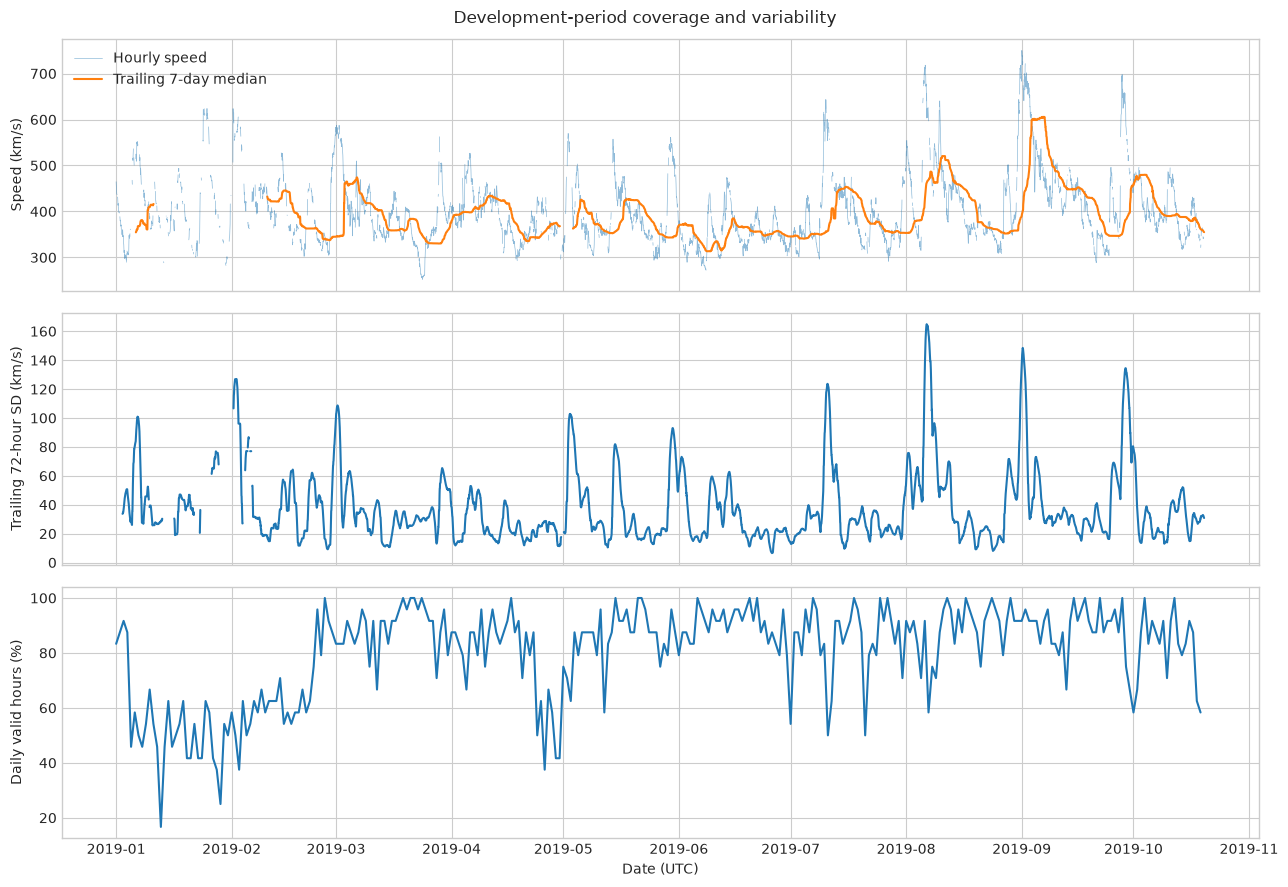

,count,median,mean,std,p10,p90
timestamp_utc,,,,,,
2019-01-01 00:00:00+00:00,398,387.70,405.211809,80.019825,308.60,521.01
2019-02-01 00:00:00+00:00,436,402.10,413.423394,77.423499,328.90,531.35
2019-03-01 00:00:00+00:00,665,382.40,389.013233,65.656340,325.80,466.12
2019-04-01 00:00:00+00:00,558,383.65,387.172222,47.694738,324.70,446.16
2019-05-01 00:00:00+00:00,639,378.10,397.003599,65.916982,321.18,503.66
2019-06-01 00:00:00+00:00,650,345.25,350.282462,38.911515,305.18,400.73
2019-07-01 00:00:00+00:00,627,370.50,388.476236,67.088738,318.36,463.98
2019-08-01 00:00:00+00:00,659,408.30,432.885129,95.101943,343.10,564.22
2019-09-01 00:00:00+00:00,642,448.20,460.413240,104.084139,341.70,642.09


In [3]:
speed = dev.speed_km_s
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
axes[0].plot(speed.index, speed, linewidth=0.5, alpha=0.5, label="Hourly speed")
axes[0].plot(speed.rolling(24 * 7, min_periods=24 * 4).median(), label="Trailing 7-day median")
axes[0].set_ylabel("Speed (km/s)")
axes[0].legend()
axes[1].plot(speed.rolling(72, min_periods=36).std())
axes[1].set_ylabel("Trailing 72-hour SD (km/s)")
axes[2].plot(speed.notna().resample("D").mean().mul(100))
axes[2].set_ylabel("Daily valid hours (%)")
axes[2].set_xlabel("Date (UTC)")
fig.suptitle("Development-period coverage and variability")
fig.tight_layout()
plt.show()
monthly = speed.resample("MS").agg(["count", "median", "mean", "std"])
monthly["p10"] = speed.resample("MS").quantile(0.1)
monthly["p90"] = speed.resample("MS").quantile(0.9)
display(monthly)


## Autocorrelation with gaps and contiguous-segment PACF

The first plot uses pairwise Pearson correlation at each exact hourly lag and reports pair counts. It is a descriptive lag-correlation curve, not the classical full-sample ACF estimator. PACF and classical ACF use only the longest contiguous valid segment, capped at 180 days. That segment may overrepresent a particular regime. No missing interval is compressed or interpolated. Confidence bands are omitted because serial dependence and segment selection complicate their interpretation.


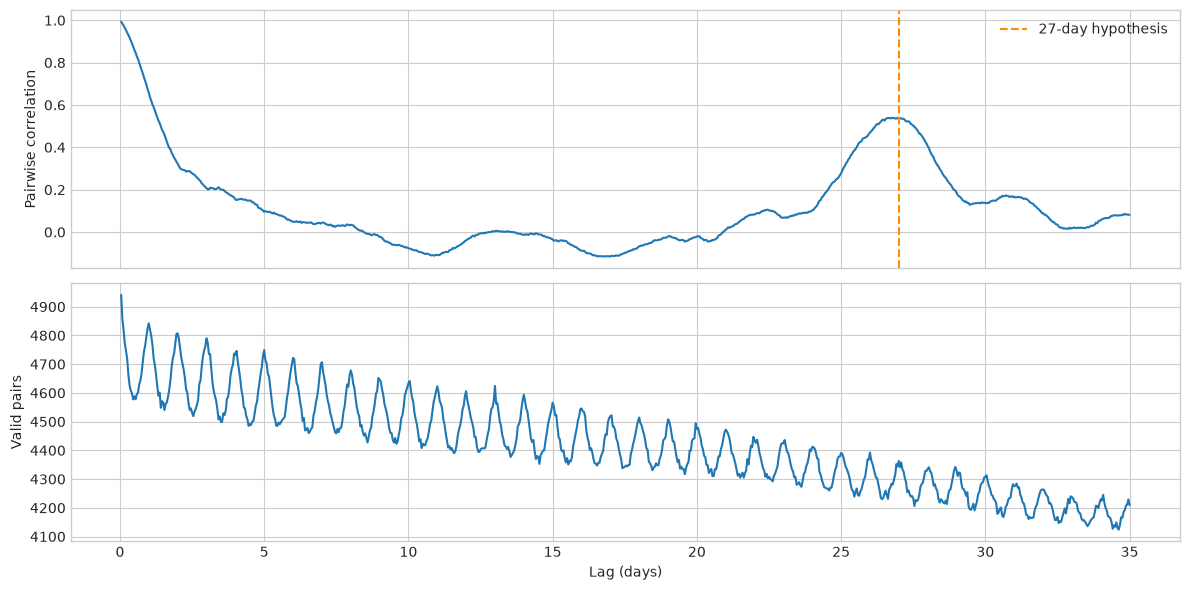

Contiguous hourly segment: 79 hours; 2019-05-20 14:00:00+00:00 to 2019-05-23 20:00:00+00:00


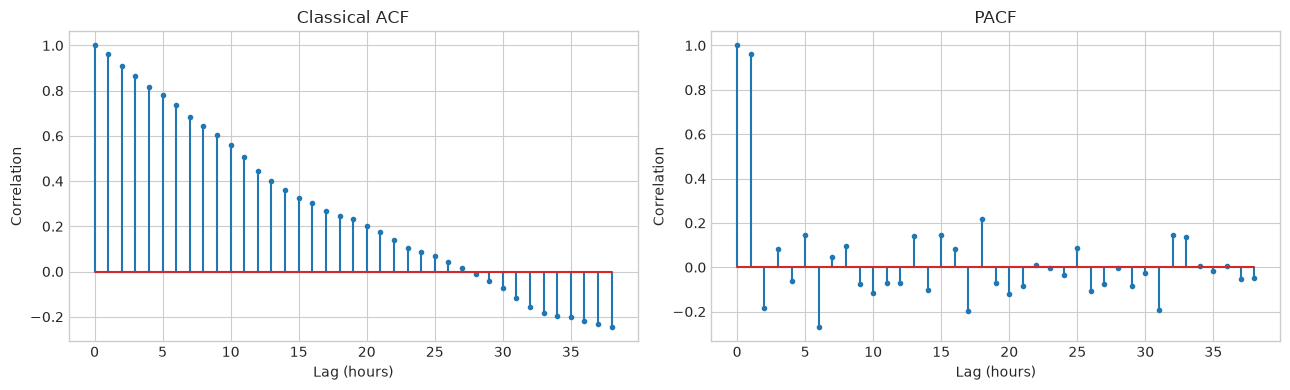

In [4]:
def longest_valid_segment(values):
    valid = values.notna()
    if not valid.any():
        return values.iloc[:0]
    groups = valid.ne(valid.shift()).cumsum()
    group_id = groups[valid].value_counts().idxmax()
    return values.loc[groups.eq(group_id) & valid]

lag_rows = []
for lag in range(1, min(24 * 35, len(speed) // 3) + 1):
    pairs = pd.concat([speed.rename("now"), speed.shift(lag).rename("past")], axis=1).dropna()
    r = pairs["now"].corr(pairs["past"]) if len(pairs) >= 30 else np.nan
    lag_rows.append((lag, r, len(pairs)))
lag_table = pd.DataFrame(lag_rows, columns=["lag_hours", "correlation", "valid_pairs"])
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(12, 6))
axes[0].plot(lag_table.lag_hours / 24, lag_table.correlation)
axes[0].axvline(27, color="darkorange", linestyle="--", label="27-day hypothesis")
axes[0].set_ylabel("Pairwise correlation")
axes[0].legend()
axes[1].plot(lag_table.lag_hours / 24, lag_table.valid_pairs)
axes[1].set(xlabel="Lag (days)", ylabel="Valid pairs")
fig.tight_layout()
plt.show()
segment = longest_valid_segment(speed).iloc[:24 * 180]
print(f"Contiguous hourly segment: {len(segment):,} hours; {segment.index.min()} to {segment.index.max()}")
if len(segment) >= 48 and segment.std() > 0:
    nlags = min(72, len(segment) // 2 - 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, values, title in [(axes[0], acf(segment, nlags=nlags, fft=True), "Classical ACF"),
                               (axes[1], pacf(segment, nlags=nlags, method="ywm"), "PACF")]:
        ax.stem(np.arange(len(values)), values, markerfmt=".")
        ax.set(xlabel="Lag (hours)", ylabel="Correlation", title=title)
    fig.tight_layout()
    plt.show()
else:
    print("ACF/PACF skipped: no sufficiently long, varying contiguous segment.")


## Spectral structure and stationarity diagnostics

The detrended periodogram uses the same complete hourly segment. Peaks are exploratory and can reflect finite-window effects or regime changes. ADF has a unit-root null; KPSS has a level-stationarity null. Their p-values are conditional diagnostics, not proof that a forecasting process is stationary. Both tests use a constant term and at most 24 lags.


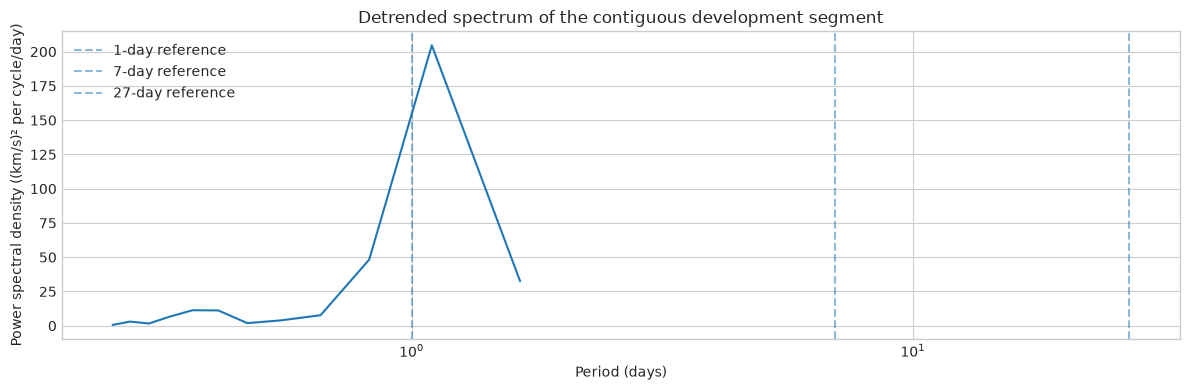

,ADF statistic,ADF p-value,KPSS statistic,KPSS p-value,Notes
Series,,,,,
Speed,-1.471368,0.547625,0.456716,0.052709,adfuller currently returns a plain tuple whose...
Hourly speed difference,-4.226232,0.000595,0.158061,0.100000,adfuller currently returns a plain tuple whose...


In [5]:
if len(segment) >= 48 and segment.std() > 0:
    frequencies, power = periodogram(segment.to_numpy(), fs=24, detrend="linear")
    positive = frequencies > 0
    periods = 1 / frequencies[positive]
    mask = (periods >= 0.25) & (periods <= len(segment) / 48)
    plt.semilogx(periods[mask], power[positive][mask])
    for day in [1, 7, 27]:
        plt.axvline(day, linestyle="--", alpha=0.5, label=f"{day}-day reference")
    plt.xlabel("Period (days)")
    plt.ylabel("Power spectral density ((km/s)² per cycle/day)")
    plt.title("Detrended spectrum of the contiguous development segment")
    plt.legend()
    plt.tight_layout()
    plt.show()
    results = []
    for name, values in [("Speed", segment), ("Hourly speed difference", segment.diff().dropna())]:
        with warnings.catch_warnings(record=True) as caught:
            a = adfuller(values, maxlag=min(24, len(values) // 2 - 2), regression="c", autolag="AIC")
            k = kpss(values, regression="c", nlags=min(24, len(values) // 4))
        results.append({"Series": name, "ADF statistic": a[0], "ADF p-value": a[1],
                        "KPSS statistic": k[0], "KPSS p-value": k[1],
                        "Notes": "; ".join(str(w.message) for w in caught)})
    display(pd.DataFrame(results).set_index("Series"))


## STL decomposition: daily and solar-rotation hypotheses

STL is applied only to contiguous data: a 24-hour component on hourly measurements, and a 27-day component on daily medians with at least 18 valid hours per day. A 27-day period is approximate and must not be treated as established seasonality. At least three complete cycles are required. The hourly fit is capped at 90 days; the daily fit at two years.

**These decompositions are retrospective diagnostics.** STL uses observations on both sides of a timestamp. Its trend, seasonal component, and residual are never added to the forecasting features below. Daily medians are also used only for diagnostics here.


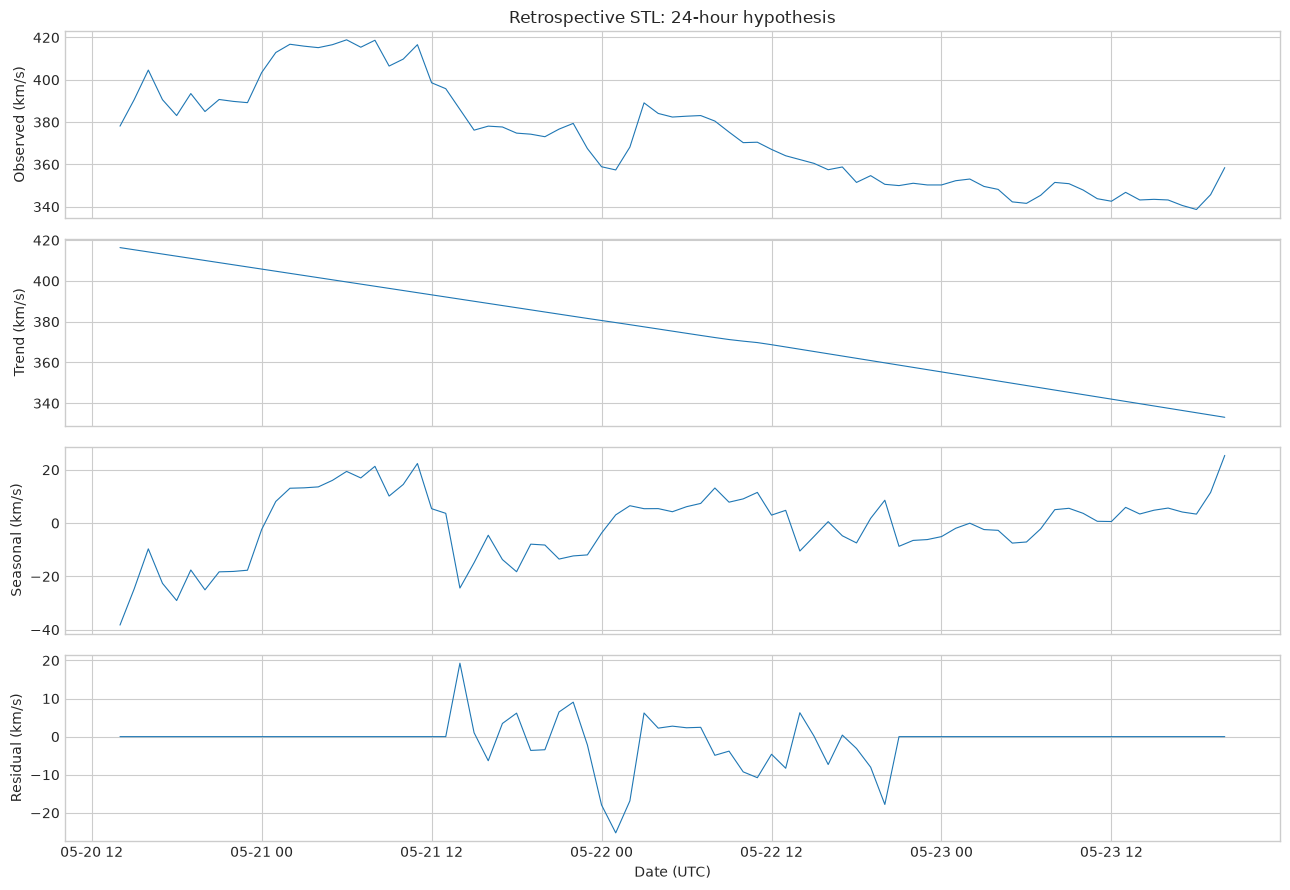

27-day hypothesis: skipped; need at least 81 contiguous valid samples.


In [6]:
daily_count = speed.resample("D").count()
daily_speed = speed.resample("D").median().where(daily_count >= 18)
decomposition_inputs = [
    ("24-hour hypothesis", segment.iloc[:24 * 90], 24),
    ("27-day hypothesis", longest_valid_segment(daily_speed).iloc[:730], 27),
]
for title, values, period in decomposition_inputs:
    if len(values) < 3 * period or values.std() == 0:
        print(f"{title}: skipped; need at least {3 * period} contiguous valid samples.")
        continue
    fitted = STL(values, period=period, robust=True).fit()
    fig, axes = plt.subplots(4, 1, sharex=True, figsize=(13, 9))
    for ax, data, label in zip(axes, [values, fitted.trend, fitted.seasonal, fitted.resid],
                              ["Observed", "Trend", "Seasonal", "Residual"]):
        ax.plot(data.index, data, linewidth=0.8)
        ax.set_ylabel(f"{label} (km/s)")
    axes[0].set_title(f"Retrospective STL: {title}")
    axes[-1].set_xlabel("Date (UTC)")
    fig.tight_layout()
    plt.show()


## Causal feature construction

At origin `t`, all inputs come from timestamps no later than `t - LATENCY_HOURS`. Features include delayed measurements, lagged speed, trailing means and variability, changes, coverage, missingness, and time since the last valid measurement. A 27-day lag tests recurrence. Rolling summaries require at least half of their window to be valid. No backward fill or interpolation is used. Age features carry the timestamp of the latest past observation, not its measured value.


In [7]:
def build_features(frame, latency_hours=1):
    if latency_hours < 1:
        raise ValueError("Use at least one hour of latency in this protocol.")
    available = frame.shift(latency_hours)
    features = pd.DataFrame(index=frame.index)
    for column in frame.columns:
        s = available[column]
        features[f"{column}_latest"] = s
        features[f"{column}_missing"] = s.isna().astype(float)
        timestamps = pd.Series(frame.index, index=frame.index).where(frame[column].notna()).ffill()
        last_available = timestamps.shift(latency_hours)
        features[f"{column}_age_hours"] = (
            pd.Series(frame.index, index=frame.index) - last_available).dt.total_seconds() / 3600
    s = available.speed_km_s
    for lag in [6, 24, 72, 168, 648]:
        features[f"speed_lag_{lag}h"] = s.shift(lag)
    for window in [6, 24, 72, 168]:
        roll = s.rolling(window, min_periods=max(2, window // 2))
        features[f"speed_mean_{window}h"] = roll.mean()
        features[f"speed_std_{window}h"] = roll.std()
        features[f"speed_coverage_{window}h"] = s.notna().rolling(window, min_periods=window).mean()
    for lag in [6, 24]:
        features[f"speed_change_{lag}h"] = s - s.shift(lag)
    return features

features = build_features(dev, LATENCY_HOURS)
targets = pd.DataFrame({h: dev.speed_km_s.shift(-h) for h in HORIZONS})
# Verify that changing future measurements cannot alter earlier features.
cut = len(dev) // 2
perturbed = dev.copy()
perturbed.iloc[cut + 1:] = 12345.0
pd.testing.assert_frame_equal(features.iloc[:cut + 1],
                              build_features(perturbed, LATENCY_HOURS).iloc[:cut + 1])
print("Passed: future perturbations do not change past features.")
display(features.isna().mean().mul(100).sort_values(ascending=False)
        .rename("Feature missing values (%)").to_frame())


Passed: future perturbations do not change past features.


,Feature missing values (%)
speed_change_6h,32.676941
speed_change_24h,30.907534
speed_lag_648h,27.140411
speed_lag_168h,21.289954
speed_lag_72h,20.134132
speed_lag_24h,19.620434
speed_lag_6h,19.463470
temperature_k_latest,19.420662
density_cm3_latest,19.406393
speed_km_s_latest,19.406393


## Feature associations and redundancy

The first half of development data is used for exploratory feature-target correlations so later validation periods do not drive this ranking. Spearman correlations measure monotonic association; they do not establish incremental skill beyond persistence. The feature matrix highlights redundancy. No features are selected automatically from these plots.


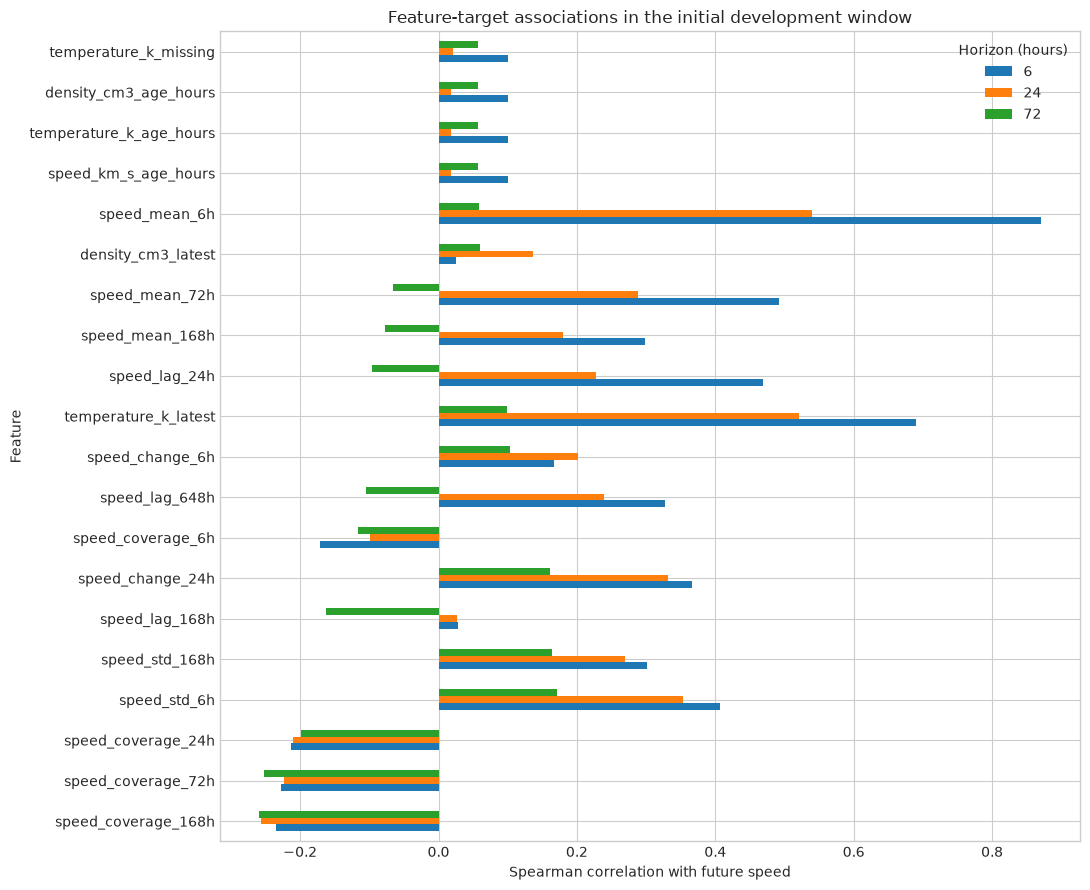

,6,24,72
Valid feature-target pairs,,,
speed_coverage_168h,2415.0,2421.0,2434.0
speed_coverage_72h,2468.0,2469.0,2486.0
speed_coverage_24h,2511.0,2513.0,2511.0
speed_std_6h,2099.0,2283.0,2286.0
speed_std_168h,2221.0,2225.0,2244.0
speed_lag_168h,1792.0,1933.0,1944.0
speed_change_24h,1637.0,1788.0,1771.0
speed_coverage_6h,2526.0,2528.0,2527.0
speed_lag_648h,1572.0,1659.0,1664.0


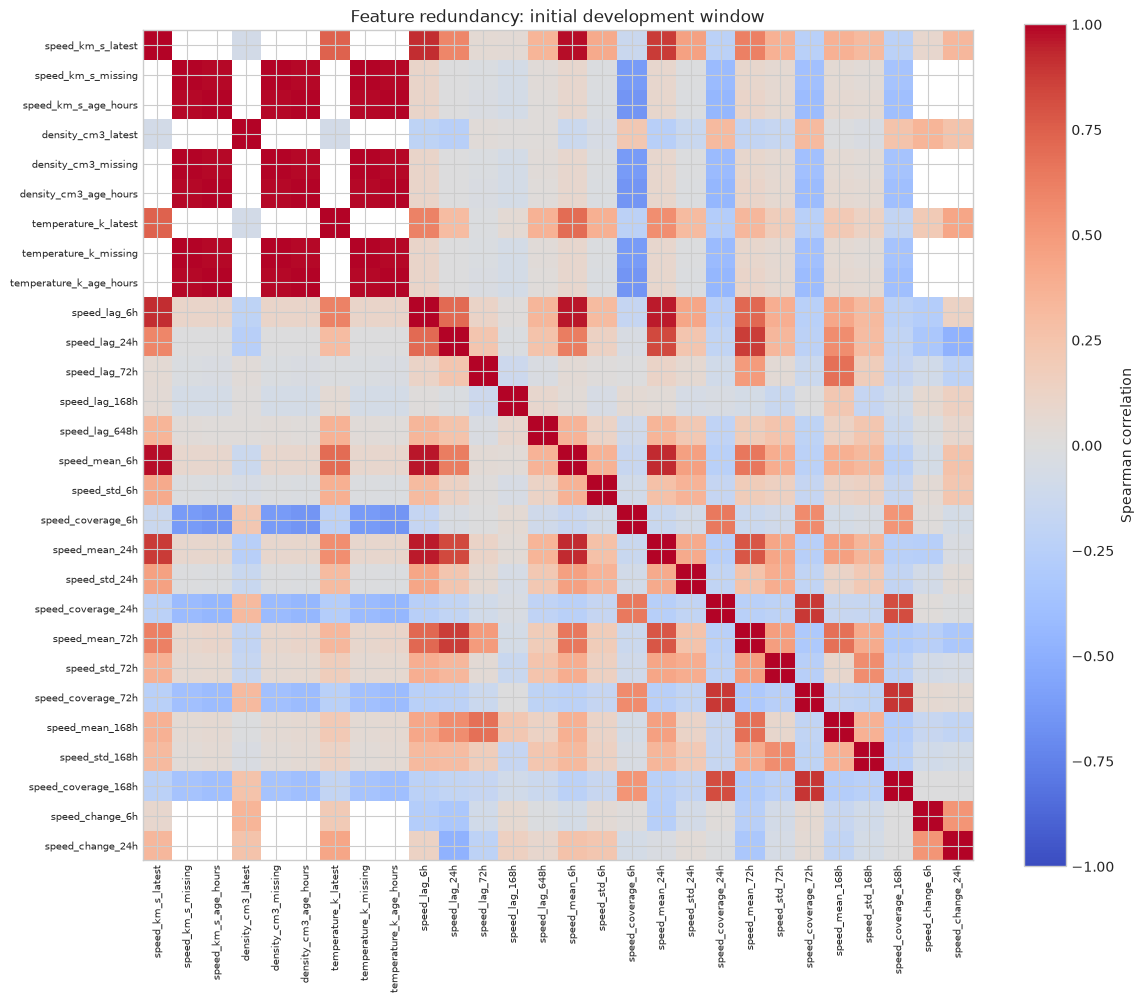

In [8]:
screen_end = dev.index[len(dev) // 2]
screen_mask = (features.index < screen_end - pd.Timedelta(hours=MAX_HORIZON))
association = pd.DataFrame(index=features.columns, columns=HORIZONS, dtype=float)
counts = association.copy()
for h in HORIZONS:
    for column in features:
        pairs = pd.concat([features.loc[screen_mask, column].rename("feature"),
                           targets.loc[screen_mask, h].rename("target")], axis=1).dropna()
        counts.loc[column, h] = len(pairs)
        if len(pairs) >= 30 and pairs.nunique().min() > 1:
            association.loc[column, h] = pairs.feature.corr(pairs.target, method="spearman")
order = association[72].abs().sort_values(ascending=False).index
association.loc[order].head(20).plot.barh(figsize=(11, 9))
plt.xlabel("Spearman correlation with future speed")
plt.ylabel("Feature")
plt.title("Feature-target associations in the initial development window")
plt.legend(title="Horizon (hours)")
plt.tight_layout()
plt.show()
display(counts.loc[order].head(20).rename_axis("Valid feature-target pairs"))
correlation = features.loc[screen_mask].corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(correlation)), correlation.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(correlation)), correlation.index, fontsize=7)
ax.set_title("Feature redundancy: initial development window")
fig.colorbar(im, ax=ax, label="Spearman correlation")
fig.tight_layout()
plt.show()


## Expanding-window backtest and feature ablation

Compare training climatology, delayed persistence, 27-day recurrence, a speed-only Ridge model, and a Ridge model using all features. The recurrence forecast at horizon `h` uses the observation at `t + h - 648 hours`; the configured horizons ensure this is already in the past.

Three expanding folds cover the last half of development data. Forecast origins occur at 00, 06, 12, and 18 UTC. Training labels must precede validation; validation labels must remain inside their fold. Preprocessing is fitted separately on each training fold. The fixed Ridge penalty is a starting point, not a tuned result. Missing features are median-imputed using training data only, with missingness indicators. Missing targets remain excluded.

RMSE, MAE, bias, model coverage, and paired skill relative to persistence are reported. All model comparisons use the same valid origins for each horizon. This common subset may underrepresent periods with gaps, so coverage is reported separately. Overlapping forecasts are dependent; no independent-sample confidence intervals are claimed.


,Fold,Training origins,Validation origins,Validation start,Validation stop
0,1,572,183,2019-05-27 00:00:00+00:00,2019-07-14 16:00:00+00:00
1,2,767,183,2019-07-14 16:00:00+00:00,2019-09-01 08:00:00+00:00
2,3,962,182,2019-09-01 08:00:00+00:00,2019-10-20 00:00:00+00:00


,Horizon,Model,Origins,Valid targets,Predictions on valid targets,Prediction coverage (%)
0,6,Climatology,548,486,486,100.000000
1,6,Persistence,548,486,440,90.534979
2,6,27-day recurrence,548,486,427,87.860082
3,6,Ridge: speed features,548,486,486,100.000000
4,6,Ridge: all features,548,486,486,100.000000
5,24,Climatology,548,486,486,100.000000
6,24,Persistence,548,486,436,89.711934
7,24,27-day recurrence,548,486,428,88.065844
8,24,Ridge: speed features,548,486,486,100.000000
9,24,Ridge: all features,548,486,486,100.000000


,Horizon,Model,Paired origins,RMSE (km/s),MAE (km/s),Bias (km/s),RMSE skill vs persistence
0,6,Climatology,387,82.489365,59.857527,-11.423806,-1.936640
1,6,Persistence,387,28.089708,19.862274,1.389406,0.000000
2,6,27-day recurrence,387,70.401820,53.050904,2.280362,-1.506321
3,6,Ridge: speed features,387,29.004248,20.436770,0.409348,-0.032558
4,6,Ridge: all features,387,27.074193,19.265093,0.146977,0.036153
5,24,Climatology,382,76.850218,56.916577,-7.957110,-0.138223
6,24,Persistence,382,67.517736,47.081675,2.406283,0.000000
7,24,27-day recurrence,382,71.455992,54.557330,4.391361,-0.058329
8,24,Ridge: speed features,382,61.330471,41.856359,-3.924300,0.091639
9,24,Ridge: all features,382,61.571621,41.356380,-3.827556,0.088067


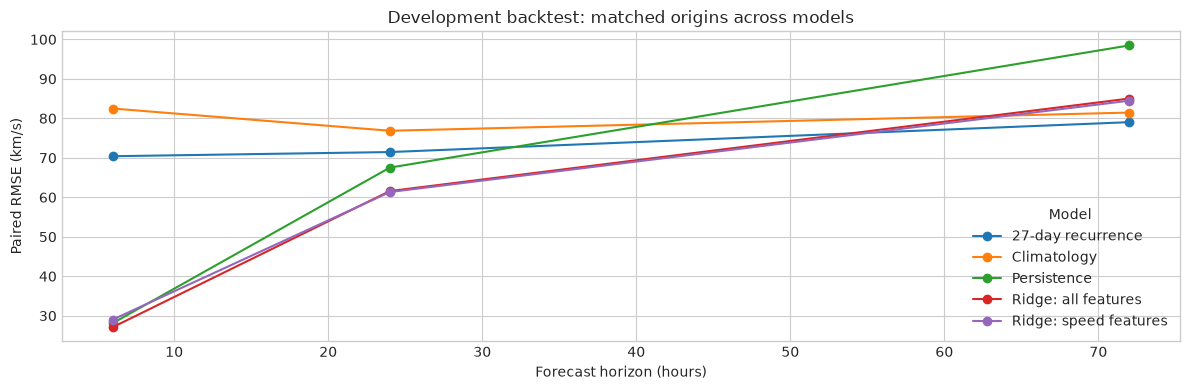

In [9]:
origins = features.index[features.index.hour % 6 == 0]
boundaries = [dev.index[int(len(dev) * f)] for f in [0.5, 2/3, 5/6]] + [holdout_start]
speed_features = [c for c in features if not c.startswith(("density_", "temperature_"))]
feature_sets = {"Ridge: speed features": speed_features, "Ridge: all features": list(features)}
fold_rows, predictions, fitted_models = [], [], {}
for fold in range(3):
    validation_start, validation_stop = boundaries[fold:fold + 2]
    train_origins = origins[origins + pd.Timedelta(hours=MAX_HORIZON) < validation_start]
    valid_origins = origins[(origins >= validation_start) &
                            (origins + pd.Timedelta(hours=MAX_HORIZON) < validation_stop)]
    fold_rows.append({"Fold": fold + 1, "Training origins": len(train_origins),
                      "Validation origins": len(valid_origins),
                      "Validation start": validation_start, "Validation stop": validation_stop})
    for h in HORIZONS:
        train_y = targets.loc[train_origins, h].dropna()
        if len(train_y) < 100 or len(valid_origins) == 0:
            continue
        out = pd.DataFrame(index=valid_origins)
        out["target"] = targets.loc[valid_origins, h]
        out["Climatology"] = train_y.mean()
        out["Persistence"] = dev.speed_km_s.shift(LATENCY_HOURS).reindex(valid_origins)
        if 648 - h < LATENCY_HOURS:
            raise ValueError("Recurrence input is unavailable at the configured latency.")
        out["27-day recurrence"] = dev.speed_km_s.shift(648 - h).reindex(valid_origins)
        for name, names in feature_sets.items():
            model = make_pipeline(SimpleImputer(strategy="median", add_indicator=True,
                                                keep_empty_features=True),
                                  StandardScaler(), Ridge(alpha=100.0))
            model.fit(features.loc[train_y.index, names], train_y)
            out[name] = model.predict(features.loc[valid_origins, names])
            fitted_models[(fold + 1, h, name)] = model
        out["fold"] = fold + 1
        out["horizon"] = h
        predictions.append(out.rename_axis("origin").reset_index())
display(pd.DataFrame(fold_rows))
if not predictions:
    raise ValueError("Insufficient valid labels for chronological backtesting.")
predictions = pd.concat(predictions, ignore_index=True)
model_names = ["Climatology", "Persistence", "27-day recurrence", *feature_sets]
coverage_rows, score_rows, common_parts = [], [], []
for h, group in predictions.groupby("horizon"):
    labeled = group.target.notna()
    for name in model_names:
        coverage_rows.append({"Horizon": h, "Model": name,
                              "Origins": len(group), "Valid targets": int(labeled.sum()),
                              "Predictions on valid targets": int((labeled & group[name].notna()).sum()),
                              "Prediction coverage (%)": 100 * group.loc[labeled, name].notna().mean()})
    common = group.dropna(subset=["target", *model_names]).copy()
    common_parts.append(common)
    reference_rmse = np.sqrt(np.mean((common.Persistence - common.target) ** 2))
    for name in model_names:
        errors = common[name] - common.target
        rmse = np.sqrt(np.mean(errors ** 2))
        score_rows.append({"Horizon": h, "Model": name, "Paired origins": len(common),
                           "RMSE (km/s)": rmse, "MAE (km/s)": errors.abs().mean(),
                           "Bias (km/s)": errors.mean(),
                           "RMSE skill vs persistence": 1 - rmse / reference_rmse if reference_rmse > 0 else np.nan})
scores = pd.DataFrame(score_rows)
common_predictions = pd.concat(common_parts, ignore_index=True)
display(pd.DataFrame(coverage_rows))
display(scores)
scores.pivot(index="Horizon", columns="Model", values="RMSE (km/s)").plot(marker="o")
plt.xlabel("Forecast horizon (hours)")
plt.ylabel("Paired RMSE (km/s)")
plt.title("Development backtest: matched origins across models")
plt.tight_layout()
plt.show()


## Fold stability, residual bias, and observed-speed regimes

Inspect whether pooled results hide a weak fold or regime. Speed bands are fixed descriptive thresholds, not official event classes. Bands use future observed speed for retrospective scoring only; they are not inputs to the forecast. The scatterplot is a calibration diagnostic, not a probabilistic calibration assessment.


Model         27-day recurrence  Climatology  Persistence  \
Fold Horizon                                                
1    6                79.703207    73.540399    25.863302   
     24               78.375733    70.029881    59.494860   
     72               82.629767    70.672345    96.746772   
2    6                58.053381    80.743973    24.901030   
     24               58.791707    75.152483    72.595080   
     72               85.319945   100.451487   112.961484   
3    6                70.601816    92.444661    32.794401   
     24               74.752589    84.798628    70.320406   
     72               68.282407    71.231880    84.547777   

Model         Ridge: all features  Ridge: speed features  
Fold Horizon                                              
1    6                  24.464516              27.440080  
     24                 57.167528              57.188262  
     72                 77.253970              75.705785  
2    6                  24.577979              27.378012  
     24                 63.071395              62.711922  
     72                105.547193             105.588259  
3    6                  31.571319              31.953732  
     24                 64.480360              64.105739  
     72                 69.528713              69.283261

,Observed-speed band,Origins,RMSE (km/s),Bias (km/s)
0,Below 400 km/s,233,50.953053,35.507136
1,400–600 km/s,134,85.121948,-70.871481
2,Above 600 km/s,15,281.030012,-276.984450


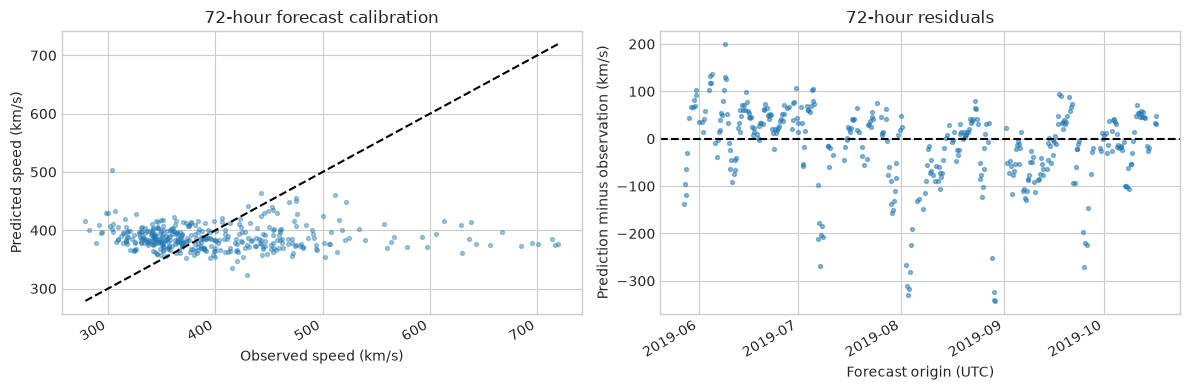

In [10]:
if not common_predictions.empty:
    fold_scores = []
    for (fold, h), group in common_predictions.groupby(["fold", "horizon"]):
        for name in model_names:
            fold_scores.append({"Fold": fold, "Horizon": h, "Model": name,
                                "RMSE (km/s)": np.sqrt(np.mean((group[name] - group.target) ** 2))})
    display(pd.DataFrame(fold_scores).pivot(index=["Fold", "Horizon"], columns="Model", values="RMSE (km/s)"))
    selected = common_predictions.loc[common_predictions.horizon == 72].copy()
    selected["regime"] = pd.cut(selected.target, [-np.inf, 400, 600, np.inf],
                                 labels=["Below 400 km/s", "400–600 km/s", "Above 600 km/s"], right=False)
    selected["error"] = selected["Ridge: all features"] - selected.target
    regime_rows = []
    for regime, group in selected.groupby("regime", observed=True):
        regime_rows.append({"Observed-speed band": regime, "Origins": len(group),
                            "RMSE (km/s)": np.sqrt(np.mean(group.error ** 2)),
                            "Bias (km/s)": group.error.mean()})
    display(pd.DataFrame(regime_rows))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].scatter(selected.target, selected["Ridge: all features"], s=8, alpha=0.4)
    if len(selected):
        limits = [min(selected.target.min(), selected["Ridge: all features"].min()),
                  max(selected.target.max(), selected["Ridge: all features"].max())]
        axes[0].plot(limits, limits, "k--")
    axes[0].set(xlabel="Observed speed (km/s)", ylabel="Predicted speed (km/s)", title="72-hour forecast calibration")
    axes[1].scatter(selected.origin, selected.error, s=8, alpha=0.5)
    axes[1].axhline(0, color="black", linestyle="--")
    axes[1].set(xlabel="Forecast origin (UTC)", ylabel="Prediction minus observation (km/s)", title="72-hour residuals")
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()


## Validation permutation importance

Measure how shuffling each feature changes the fixed model's RMSE on the last development fold at 72 hours. Positive values indicate worse predictions after shuffling. Correlated features can mask each other's contribution, and row-wise permutations break temporal structure. Treat this as an exploratory model diagnostic, not a causal ranking or an uncertainty estimate. Feature ablation and fold stability above provide complementary evidence. The final holdout remains untouched.


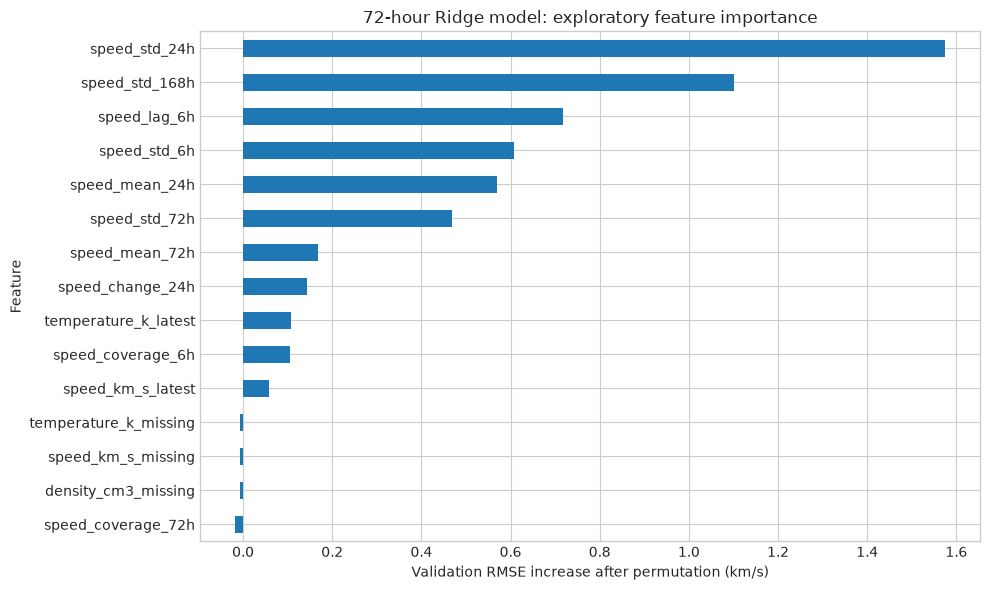

,RMSE increase (km/s),Permutation SD
Feature,,
speed_std_24h,1.573478,0.554620
speed_std_168h,1.100781,0.565746
speed_lag_6h,0.716641,0.247186
speed_std_6h,0.607037,0.686628
speed_mean_24h,0.569571,0.148689
speed_std_72h,0.467946,0.306003
speed_mean_72h,0.168884,0.156530
speed_change_24h,0.142723,0.292119
temperature_k_latest,0.106910,0.042256


In [11]:
key = (3, 72, "Ridge: all features")
last = predictions.loc[(predictions.fold == 3) & (predictions.horizon == 72)].dropna(subset=["target"])
if key in fitted_models and len(last) >= 30:
    importance = permutation_importance(
        fitted_models[key], features.loc[pd.DatetimeIndex(last.origin)], last.target.to_numpy(),
        scoring="neg_root_mean_squared_error", n_repeats=3, random_state=SEED, n_jobs=1)
    ranking = pd.DataFrame({"Feature": features.columns,
                            "RMSE increase (km/s)": importance.importances_mean,
                            "Permutation SD": importance.importances_std}).set_index("Feature")
    ranking = ranking.sort_values("RMSE increase (km/s)")
    ranking.tail(15)["RMSE increase (km/s)"].plot.barh(figsize=(10, 6))
    plt.xlabel("Validation RMSE increase after permutation (km/s)")
    plt.title("72-hour Ridge model: exploratory feature importance")
    plt.tight_layout()
    plt.show()
    display(ranking.sort_values("RMSE increase (km/s)", ascending=False).head(15))
else:
    print("Permutation importance skipped: too few valid final-fold observations.")


## Next experiments before a final forecast assessment

1. Repeat development backtests with plausible publication delays (for example 1, 3, and 6 hours). Verify the operational source latency before deployment.
2. Compare feature groups on identical folds and origins. Keep changes only if gains persist across folds, horizons, coverage levels, and speed regimes.
3. Expand to every hourly horizon from 1 to 72 and reproduce the official evaluation contract once confirmed. The metrics here are local unweighted diagnostics.
4. Investigate recurrent residual structure and abrupt speed changes. Add external inputs only after verifying their historical availability and quality.
5. Freeze preprocessing, feature choices, and model settings before evaluating the reserved final holdout once. Because an earlier exploration notebook may have displayed the entire dataset, a stricter blind evaluation may require a new untouched period.
6. Evaluate operational fallbacks, missing-input behavior, CPU time, and memory. These are outside this offline diagnostic notebook.

The notebook does not promote a model automatically, impute missing labels, or claim that in-sample seasonality implies forecasting skill.
